In [7]:
!pip install numpy scipy matplotlib soundfile scikit-learn


In [8]:
import numpy as np
from google.colab import files
import matplotlib.pyplot as plt
import soundfile as sf

from scipy.signal import resample_poly
from pathlib import Path
from IPython.display import Audio, display

In [9]:
uploaded = files.upload()

print("\nUploaded files:")

for filename in uploaded:
    print(filename)

Saving female.wav to female (1).wav
Saving instrumental.wav to instrumental (1).wav
Saving male.wav to male (1).wav

Uploaded files:
female (1).wav
instrumental (1).wav
male (1).wav


In [10]:
source_files = [
    "male.wav",
    "female.wav",
    "instrumental.wav"
]

sources = []
sample_rates = []

for filename in source_files:

    audio, sr = sf.read(filename)


    if audio.ndim == 2:
        audio = audio.mean(axis=1)

    audio = audio.astype(np.float64)

    sources.append(audio)
    sample_rates.append(sr)

    duration = len(audio) / sr

    print(f"\nFile: {filename}")
    print(f"Sample rate: {sr} Hz")
    print(f"Duration: {duration:.2f} seconds")
    print(f"Number of samples: {len(audio)}")

print("\nAll three audio files loaded successfully!")


File: male.wav
Sample rate: 44100 Hz
Duration: 31.63 seconds
Number of samples: 1395072

File: female.wav
Sample rate: 44100 Hz
Duration: 28.60 seconds
Number of samples: 1261440

File: instrumental.wav
Sample rate: 44100 Hz
Duration: 30.41 seconds
Number of samples: 1340928

All three audio files loaded successfully!


In [11]:
target_sr = 16000

processed_sources = []

for audio, sr in zip(sources, sample_rates):


    if sr != target_sr:
        from math import gcd

        common = gcd(target_sr, sr)

        audio = resample_poly(
            audio,
            target_sr // common,
            sr // common
        )

    processed_sources.append(audio)


min_length = min(len(audio) for audio in processed_sources)

processed_sources = [
    audio[:min_length]
    for audio in processed_sources
]


S = np.vstack(processed_sources)

print("Source matrix shape:", S.shape)
print("Sample rate:", target_sr, "Hz")
print("Duration:", S.shape[1] / target_sr, "seconds")

Source matrix shape: (3, 457666)
Sample rate: 16000 Hz
Duration: 28.604125 seconds


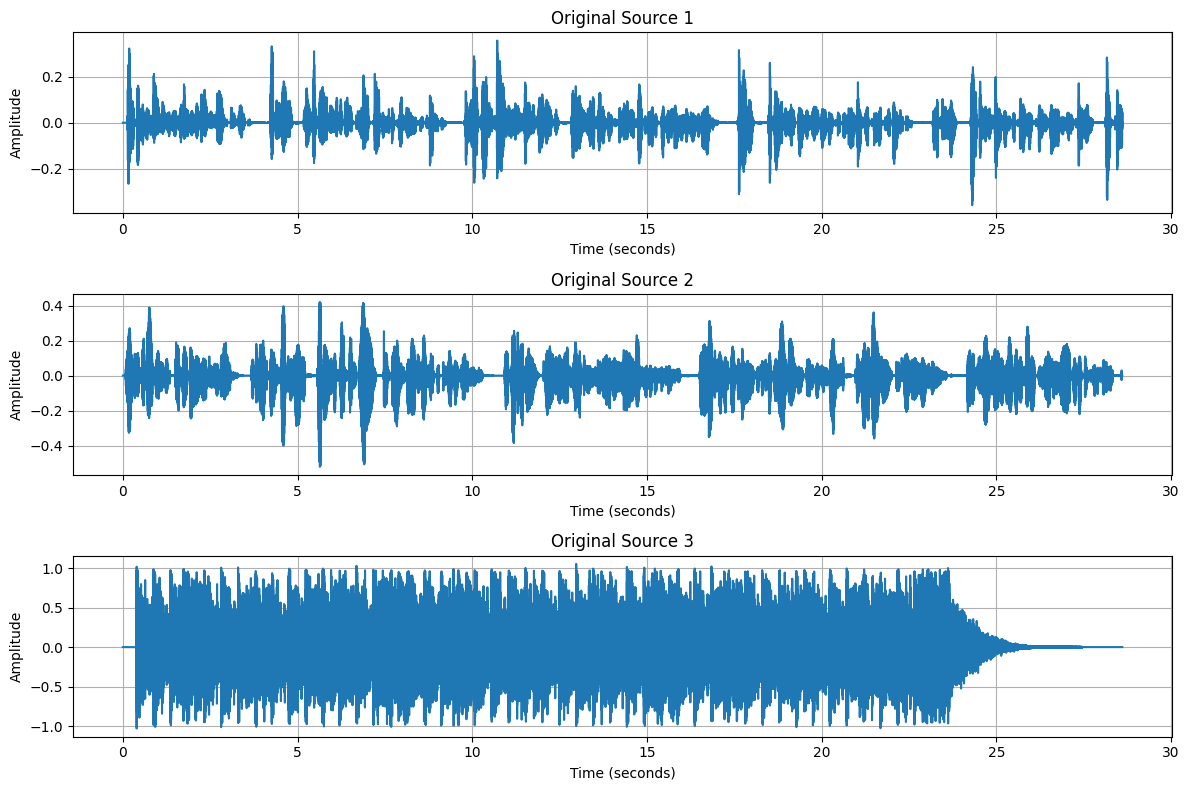

In [12]:
time = np.arange(S.shape[1]) / target_sr

fig, axes = plt.subplots(3, 1, figsize=(12, 8))

for i in range(3):
    axes[i].plot(time, S[i])
    axes[i].set_title(f"Original Source {i + 1}")
    axes[i].set_xlabel("Time (seconds)")
    axes[i].set_ylabel("Amplitude")
    axes[i].grid(True)

plt.tight_layout()
plt.show()

In [13]:
print(S.shape)
print(S.shape[1] / target_sr)

(3, 457666)
28.604125


In [14]:
A = np.array([
    [0.7, 0.2, 0.1],
    [0.1, 0.8, 0.3],
    [0.3, 0.1, 0.9]
])

print("Mixing Matrix A:")
print(A)

print("\nDeterminant:", np.linalg.det(A))

Mixing Matrix A:
[[0.7 0.2 0.1]
 [0.1 0.8 0.3]
 [0.3 0.1 0.9]]

Determinant: 0.45999999999999996


In [15]:
X = A @ S

print("Original source matrix shape:", S.shape)
print("Mixed signal matrix shape:", X.shape)

Original source matrix shape: (3, 457666)
Mixed signal matrix shape: (3, 457666)


In [16]:
for i in range(3):
    print(f"Mixed Recording {i + 1}")

    display(
        Audio(
            X[i],
            rate=target_sr
        )
    )

Mixed Recording 1


Mixed Recording 2


Mixed Recording 3


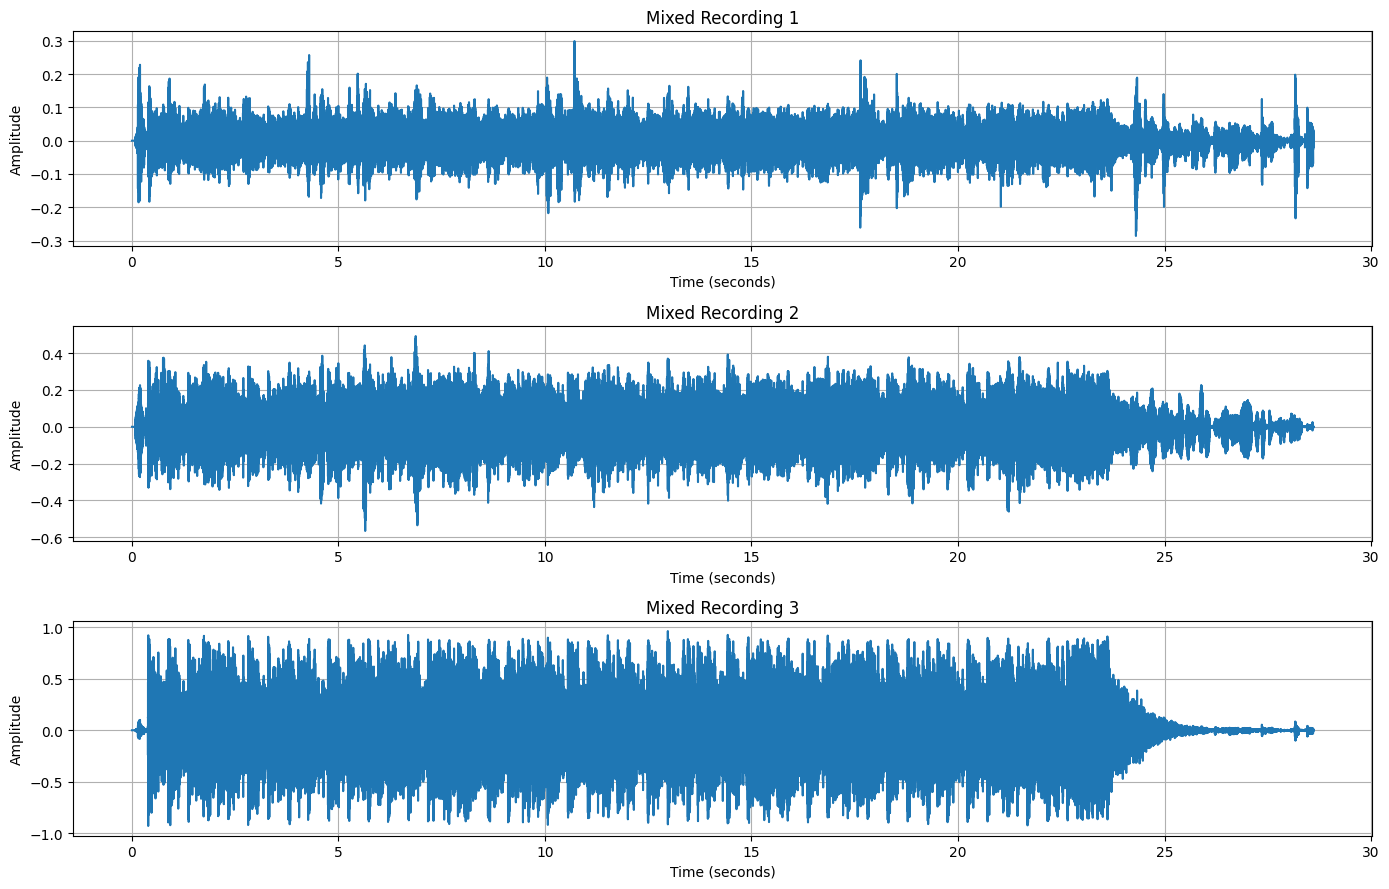

In [17]:
time = np.arange(X.shape[1]) / target_sr

fig, axes = plt.subplots(3, 1, figsize=(14, 9))

for i in range(3):
    axes[i].plot(time, X[i])
    axes[i].set_title(f"Mixed Recording {i + 1}")
    axes[i].set_xlabel("Time (seconds)")
    axes[i].set_ylabel("Amplitude")
    axes[i].grid(True)

plt.tight_layout()
plt.show()

In [18]:

mean_X = np.mean(X, axis=1, keepdims=True)


X_centered = X - mean_X

print("Original mixed signals shape:", X.shape)
print("Centered signals shape:", X_centered.shape)

print("\nMean of each centered recording:")
print(np.mean(X_centered, axis=1))

Original mixed signals shape: (3, 457666)
Centered signals shape: (3, 457666)

Mean of each centered recording:
[-1.05038733e-19  1.85576515e-18 -1.70487810e-18]


In [19]:

covariance_matrix = np.cov(X_centered)

print("Covariance matrix:")
print(covariance_matrix)



eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)


eigenvalues = np.maximum(eigenvalues, 1e-12)



whitening_matrix = (
    np.diag(1.0 / np.sqrt(eigenvalues))
    @ eigenvectors.T
)



Z = whitening_matrix @ X_centered

print("\nWhitened signals shape:", Z.shape)

print("\nCovariance matrix after whitening:")
print(np.cov(Z))

Covariance matrix:
[[0.00109722 0.00254233 0.00652752]
 [0.00254233 0.00789486 0.01929731]
 [0.00652752 0.01929731 0.0572728 ]]

Whitened signals shape: (3, 457666)

Covariance matrix after whitening:
[[ 1.00000000e+00 -5.24115412e-15  1.00254426e-15]
 [-5.24115412e-15  1.00000000e+00  2.07850663e-15]
 [ 1.00254426e-15  2.07850663e-15  1.00000000e+00]]


In [20]:
print("Mean of whitened signals:")
print(np.mean(Z, axis=1))

print("\nCovariance matrix:")
print(np.cov(Z))

print("\nVariance of each whitened signal:")
print(np.var(Z, axis=1))

Mean of whitened signals:
[-4.07773463e-17  6.30639941e-17 -4.00554172e-18]

Covariance matrix:
[[ 1.00000000e+00 -5.24115412e-15  1.00254426e-15]
 [-5.24115412e-15  1.00000000e+00  2.07850663e-15]
 [ 1.00254426e-15  2.07850663e-15  1.00000000e+00]]

Variance of each whitened signal:
[0.99999782 0.99999782 0.99999782]


In [21]:
def symmetric_decorrelation(W):

    eigenvalues, eigenvectors = np.linalg.eigh(W @ W.T)

    eigenvalues = np.maximum(eigenvalues, 1e-12)

    W_decorrelated = (
        eigenvectors
        @ np.diag(1.0 / np.sqrt(eigenvalues))
        @ eigenvectors.T
        @ W
    )

    return W_decorrelated


def fastica(Z, n_components=3, max_iter=1000, tol=1e-5, random_state=42):


    rng = np.random.default_rng(random_state)


    W = rng.standard_normal((n_components, Z.shape[0]))


    W = symmetric_decorrelation(W)

    for iteration in range(max_iter):

        W_old = W.copy()


        projections = W @ Z


        g = np.tanh(projections)


        g_derivative = 1.0 - g**2


        W_new = (
            (g @ Z.T) / Z.shape[1]
            - np.diag(np.mean(g_derivative, axis=1)) @ W
        )


        W = symmetric_decorrelation(W_new)


        convergence = np.max(
            np.abs(np.abs(np.diag(W @ W_old.T)) - 1)
        )

        if convergence < tol:
            print(f"Converged after {iteration + 1} iterations.")
            break

    else:
        print("Maximum iterations reached.")

    return W

In [22]:

W = fastica(Z, n_components=3)

print("Estimated unmixing matrix W:")
print(W)


S_estimated = W @ Z

print("\nEstimated source signals shape:")
print(S_estimated.shape)

Converged after 4 iterations.
Estimated unmixing matrix W:
[[-0.02899516 -0.07822032  0.99651436]
 [ 0.11847443 -0.99017521 -0.07427554]
 [ 0.99253367  0.11590784  0.0379774 ]]

Estimated source signals shape:
(3, 457666)


In [23]:
for i in range(3):
    print(f"Estimated Component {i + 1}")

    display(
        Audio(
            S_estimated[i],
            rate=target_sr
        )
    )

Estimated Component 1


Estimated Component 2


Estimated Component 3


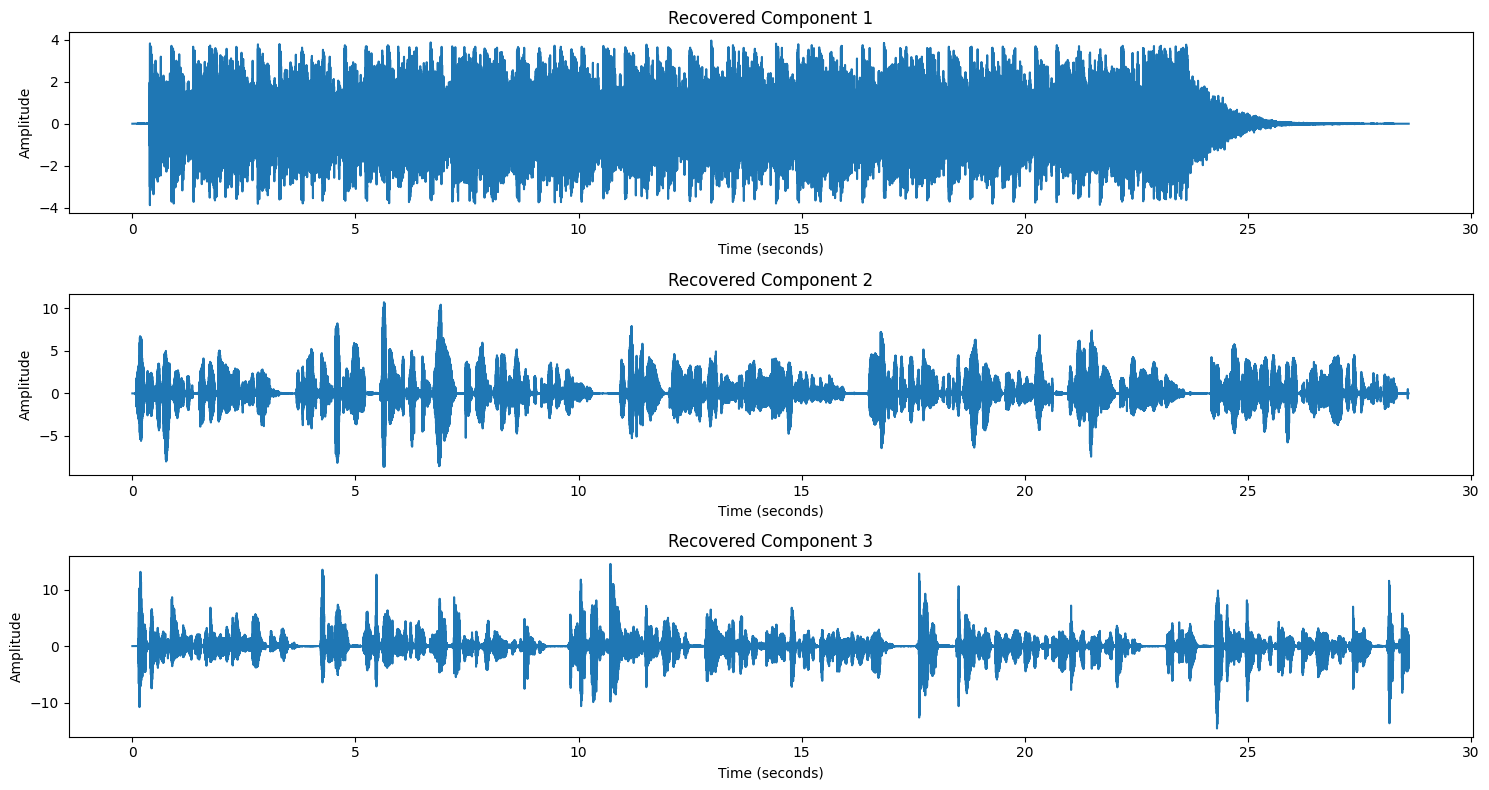

In [24]:
fig, axes = plt.subplots(3, 1, figsize=(15, 8))

for i in range(3):
    time = np.arange(S_estimated.shape[1]) / target_sr

    axes[i].plot(time, S_estimated[i])
    axes[i].set_title(f"Recovered Component {i + 1}")
    axes[i].set_xlabel("Time (seconds)")
    axes[i].set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

In [25]:

correlation_matrix = np.zeros((3, 3))

for i in range(3):
    for j in range(3):
        correlation_matrix[i, j] = abs(
            np.corrcoef(S[i], S_estimated[j])[0, 1]
        )

print("Absolute correlation matrix:")
print(correlation_matrix)

source_names = [
    "Male Speech",
    "Female Speech",
    "Instrumental Music"
]

for j in range(3):
    best_match = np.argmax(correlation_matrix[:, j])

    print(
        f"Component {j + 1} best matches: "
        f"{source_names[best_match]} "
        f"(correlation = {correlation_matrix[best_match, j]:.4f})"
    )

Absolute correlation matrix:
[[2.30888711e-03 1.51326500e-03 9.99996190e-01]
 [3.45730528e-04 9.99999231e-01 1.19099631e-03]
 [9.99997089e-01 2.39997591e-03 2.50812694e-04]]
Component 1 best matches: Instrumental Music (correlation = 1.0000)
Component 2 best matches: Female Speech (correlation = 1.0000)
Component 3 best matches: Male Speech (correlation = 1.0000)


In [26]:
import os

os.makedirs("separated_audio", exist_ok=True)

for i in range(3):

    audio = S_estimated[i].copy()

    peak = np.max(np.abs(audio))

    if peak > 0:
        audio = 0.95 * audio / peak

    output_file = f"separated_audio/component_{i + 1}.wav"

    sf.write(output_file, audio, target_sr)

    print("Saved:", output_file)

Saved: separated_audio/component_1.wav
Saved: separated_audio/component_2.wav
Saved: separated_audio/component_3.wav


In [27]:
for i in range(3):
    files.download(f"separated_audio/component_{i + 1}.wav")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
print("Absolute correlation matrix:")
print(correlation_matrix)

print("\nBest source match for each component:")

for j in range(3):
    best_match = np.argmax(correlation_matrix[:, j])

    print(
        f"Component {j + 1} -> {source_names[best_match]} "
        f"(correlation: {correlation_matrix[best_match, j]:.6f})"
    )

Absolute correlation matrix:
[[2.30888711e-03 1.51326500e-03 9.99996190e-01]
 [3.45730528e-04 9.99999231e-01 1.19099631e-03]
 [9.99997089e-01 2.39997591e-03 2.50812694e-04]]

Best source match for each component:
Component 1 -> Instrumental Music (correlation: 0.999997)
Component 2 -> Female Speech (correlation: 0.999999)
Component 3 -> Male Speech (correlation: 0.999996)


In [29]:



covariance_pca = np.cov(X_centered)


eigenvalues_pca, eigenvectors_pca = np.linalg.eigh(covariance_pca)


indices = np.argsort(eigenvalues_pca)[::-1]
eigenvectors_pca = eigenvectors_pca[:, indices]


P_pca = eigenvectors_pca.T @ X_centered

print("PCA components shape:", P_pca.shape)

PCA components shape: (3, 457666)


In [30]:


pca_correlation = np.zeros((3, 3))

for i in range(3):
    for j in range(3):
        pca_correlation[i, j] = abs(
            np.corrcoef(S[i], P_pca[j])[0, 1]
        )

print("PCA absolute correlation matrix:")
print(pca_correlation)

print("\nFastICA absolute correlation matrix:")
print(correlation_matrix)

PCA absolute correlation matrix:
[[0.03578881 0.1175864  0.99241755]
 [0.07457478 0.99000936 0.11966647]
 [0.99669924 0.07581463 0.02903047]]

FastICA absolute correlation matrix:
[[2.30888711e-03 1.51326500e-03 9.99996190e-01]
 [3.45730528e-04 9.99999231e-01 1.19099631e-03]
 [9.99997089e-01 2.39997591e-03 2.50812694e-04]]


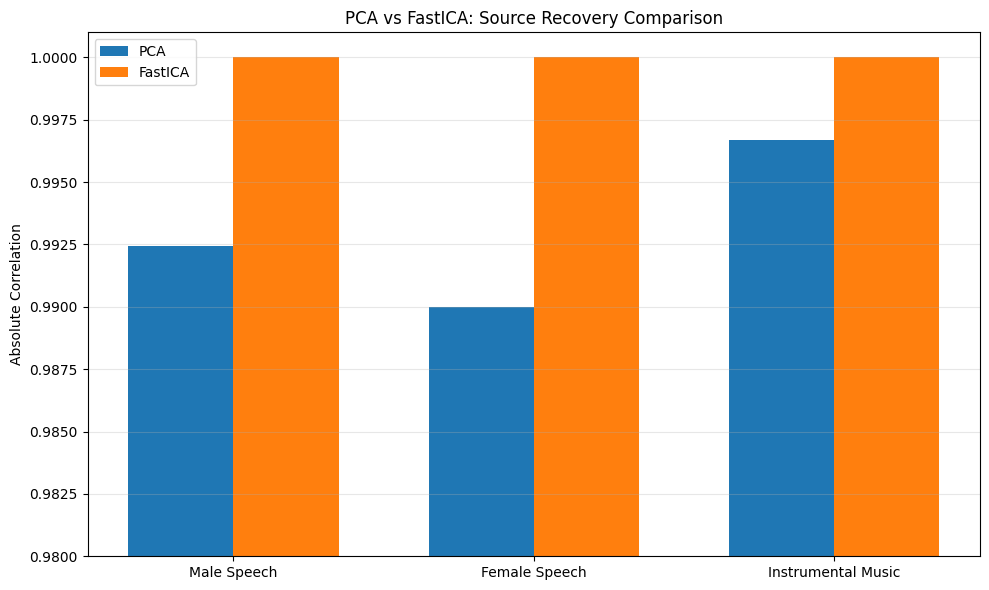

In [31]:
import matplotlib.pyplot as plt
import numpy as np

source_names = [
    "Male Speech",
    "Female Speech",
    "Instrumental Music"
]


pca_best = np.max(pca_correlation, axis=1)
ica_best = np.max(correlation_matrix, axis=0)

x = np.arange(len(source_names))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    pca_best,
    width,
    label="PCA"
)

plt.bar(
    x + width / 2,
    ica_best,
    width,
    label="FastICA"
)

plt.xticks(x, source_names)
plt.ylabel("Absolute Correlation")
plt.title("PCA vs FastICA: Source Recovery Comparison")
plt.ylim(0.98, 1.001)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
from itertools import permutations

def best_source_assignment(correlation_matrix):

    n_sources = correlation_matrix.shape[0]

    best_permutation = None
    best_score = -np.inf

    for permutation in permutations(range(n_sources)):
        score = sum(
            correlation_matrix[i, permutation[i]]
            for i in range(n_sources)
        )

        if score > best_score:
            best_score = score
            best_permutation = permutation

    return best_permutation, best_score


pca_assignment, pca_score = best_source_assignment(pca_correlation)
ica_assignment, ica_score = best_source_assignment(correlation_matrix)

print("PCA best assignment:")
for i, j in enumerate(pca_assignment):
    print(
        f"{source_names[i]} -> Component {j + 1}: "
        f"{pca_correlation[i, j]:.6f}"
    )

print("\nFastICA best assignment:")
for i, j in enumerate(ica_assignment):
    print(
        f"{source_names[i]} -> Component {j + 1}: "
        f"{correlation_matrix[i, j]:.6f}"
    )

PCA best assignment:
Male Speech -> Component 3: 0.992418
Female Speech -> Component 2: 0.990009
Instrumental Music -> Component 1: 0.996699

FastICA best assignment:
Male Speech -> Component 3: 0.999996
Female Speech -> Component 2: 0.999999
Instrumental Music -> Component 1: 0.999997


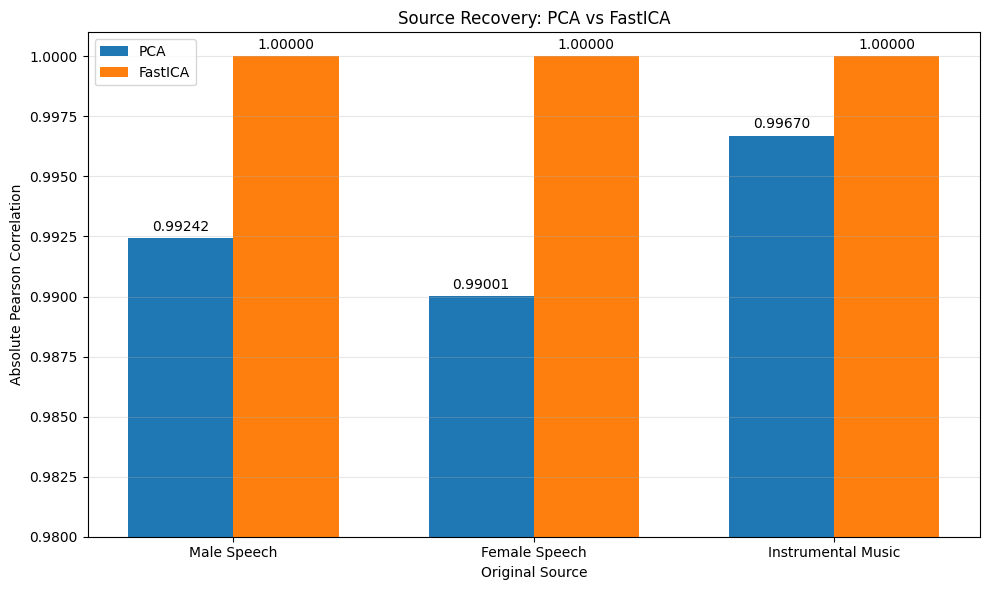

In [33]:
import matplotlib.pyplot as plt
import numpy as np

source_names = [
    "Male Speech",
    "Female Speech",
    "Instrumental Music"
]

pca_results = np.array([
    pca_correlation[i, pca_assignment[i]]
    for i in range(3)
])

ica_results = np.array([
    correlation_matrix[i, ica_assignment[i]]
    for i in range(3)
])

x = np.arange(len(source_names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width / 2,
    pca_results,
    width,
    label="PCA"
)

bars2 = ax.bar(
    x + width / 2,
    ica_results,
    width,
    label="FastICA"
)

ax.set_xlabel("Original Source")
ax.set_ylabel("Absolute Pearson Correlation")
ax.set_title("Source Recovery: PCA vs FastICA")
ax.set_xticks(x)
ax.set_xticklabels(source_names)
ax.set_ylim(0.98, 1.001)

ax.legend()
ax.grid(axis="y", alpha=0.3)

ax.bar_label(bars1, fmt="%.5f", padding=3)
ax.bar_label(bars2, fmt="%.5f", padding=3)

plt.tight_layout()
plt.savefig("pca_vs_fastica.png", dpi=300, bbox_inches="tight")
plt.show()

In [34]:
from pathlib import Path

project_dir = Path("unmix-the-signal-ica")

for path in sorted(project_dir.rglob("*")):
    print(path)

In [35]:
from pathlib import Path

project_dir = Path("unmix-the-signal-ica")

print("Current directory:", Path.cwd())
print("Project folder exists:", project_dir.exists())

if project_dir.exists():
    for path in sorted(project_dir.rglob("*")):
        print(path)
else:
    print("Project folder not found in the current directory.")

Current directory: /content
Project folder exists: False
Project folder not found in the current directory.
